# Stream A — Visual Grounding

For each named entity extracted by NER, checks whether that entity is
**visually present** in the paired image using OpenCLIP zero-shot similarity.

**Strategy:**
- For each (image, entity_list) pair, embed the image with CLIP and compare
  against text prompts like `"a photo of {entity}"` for each entity.
- Store the max entity-image similarity score per pair → used by entity_scorer
  to flag mismatches.
- NewsCLIPpings: uses pre-extracted CLIP ViT-B/32 image embeddings (no GPU needed)
- VERITE + MMFakeBench: runs CLIP on images directly (requires images on disk)

**Outputs (auto-saved):**
- `cache/visual_grounding/vg_newsclippings_{split}.pkl` — `{id: {entity_text: score}}`
- `cache/visual_grounding/vg_verite.pkl`
- `cache/visual_grounding/vg_mmfake.pkl`
- `cache/visual_grounding/vg_all.pkl` — merged
- `paper/tables/vg_stats.csv`
- `paper/figures/vg_score_distribution.png`
- `paper/figures/vg_score_ooc_vs_genuine.png`

**Order:** `ner_pipeline` → **`visual_grounding`** → `entity_scorer`

## 1. Environment

In [81]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
if torch.cuda.is_available():
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 8.6 GB


In [82]:
import sys, pickle, time
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from PIL import Image
import open_clip

sys.path.insert(0, str(Path("../../").resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

VG_CACHE     = CACHE / "visual_grounding"
NER_CACHE    = CACHE / "ner"
PAPER_FIGS   = ROOT  / "paper" / "figures"
PAPER_TABLES = ROOT  / "paper" / "tables"
for d in [VG_CACHE, PAPER_FIGS, PAPER_TABLES]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def savefig(name):
    p = PAPER_FIGS / f"{name}.png"
    plt.savefig(p, bbox_inches="tight", dpi=150)
    print(f"  Saved → {p.relative_to(ROOT)}")

def savecsv(df, name):
    p = PAPER_TABLES / f"{name}.csv"
    df.to_csv(p, index=False)
    print(f"  Saved → {p.relative_to(ROOT)}")

print(f"Device: {DEVICE}")
print(f"VG cache → {VG_CACHE.relative_to(ROOT)}")

Device: cuda
VG cache → cache\visual_grounding


## 2. Load NER caches

In [83]:
all_ner = pickle.load(open(NER_CACHE / "entities_all.pkl", "rb"))
verite_ner  = pickle.load(open(NER_CACHE / "entities_verite.pkl",  "rb"))
mmfake_ner  = pickle.load(open(NER_CACHE / "entities_mmfake.pkl",  "rb"))

# NewsCLIPpings per-split
nc_ner = {}
for split in ["train", "val", "test"]:
    p = NER_CACHE / f"entities_newsclippings_{split}.pkl"
    nc_ner[split] = pickle.load(open(p, "rb"))

print(f"  NER all      : {len(all_ner):,} entries")
print(f"  VERITE NER   : {len(verite_ner):,} entries")
print(f"  MMFake NER   : {len(mmfake_ner):,} entries")
for split, d in nc_ner.items():
    n_with = sum(1 for v in d.values() if v)
    print(f"  NC/{split:<6}   : {len(d):,} entries  ({n_with} with entities — placeholder)")

  NER all      : 53,681 entries
  VERITE NER   : 1,001 entries
  MMFake NER   : 10,000 entries
  NC/train    : 35,536 entries  (0 with entities — placeholder)
  NC/val      : 3,512 entries  (0 with entities — placeholder)
  NC/test     : 3,632 entries  (0 with entities — placeholder)


## 3. Load CLIP model

Using ViT-B/32 (matches NewsCLIPpings pre-extracted embeddings).

In [84]:
print("Loading OpenCLIP ViT-B/32 ...")
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="openai"
)
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(DEVICE).eval()

# Smoke test
with torch.no_grad():
    t = clip_tokenizer(["a photo of Barack Obama"])
    f = clip_model.encode_text(t.to(DEVICE))
print(f"  ✓  Text embedding shape: {f.shape}  (should be [1, 512])")

def encode_texts(texts, batch_size=512):
    """Encode a list of strings → L2-normalised numpy array [N, 512]."""
    vecs = []
    for i in range(0, len(texts), batch_size):
        toks = clip_tokenizer(texts[i:i+batch_size]).to(DEVICE)
        with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
            v = clip_model.encode_text(toks).float()
            v = v / v.norm(dim=-1, keepdim=True)
        vecs.append(v.cpu().numpy())
    return np.concatenate(vecs, axis=0)

def encode_images_from_paths(paths, batch_size=64):
    """Encode PIL images from file paths → L2-normalised numpy array [N, 512]."""
    vecs = []
    for i in range(0, len(paths), batch_size):
        batch = []
        for p in paths[i:i+batch_size]:
            try:
                img = clip_preprocess(Image.open(p).convert("RGB"))
            except Exception:
                img = torch.zeros(3, 224, 224)  # fallback for missing images
            batch.append(img)
        imgs = torch.stack(batch).to(DEVICE)
        with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
            v = clip_model.encode_image(imgs).float()
            v = v / v.norm(dim=-1, keepdim=True)
        vecs.append(v.cpu().numpy())
        torch.cuda.empty_cache()
    return np.concatenate(vecs, axis=0)

print("  ✓  CLIP helpers ready")

Loading OpenCLIP ViT-B/32 ...


C:\Users\User\AppData\Roaming\Python\Python313\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


  ✓  Text embedding shape: torch.Size([1, 512])  (should be [1, 512])
  ✓  CLIP helpers ready


## 4. NewsCLIPpings — visual grounding via pre-extracted embeddings

NewsCLIPpings has pre-extracted CLIP image embeddings in `cache/clip_embeddings/`.
We use those directly — no need to load images.

For each pair: score = max cosine_sim(image_emb, encode("a photo of {entity}"))
across all entities in the caption. Pairs with no entities get score = NaN.

In [85]:
def newsclip_vg_split(split, nc_ner_split):
    """Compute visual grounding scores for one NewsCLIPpings split."""
    out_path = VG_CACHE / f"vg_newsclippings_{split}.pkl"
    if out_path.exists():
        res = pickle.load(open(out_path, "rb"))
        print(f"  ✓  NC/{split}: loaded from cache ({len(res):,} entries)")
        return res

    # Load pre-extracted image embeddings
    img_emb_path = CLIP_EMB / "clip_image_embeddings" / f"{split}.pkl"
    if not img_emb_path.exists():
        print(f"  ✗  {img_emb_path} not found — skipping NC/{split}")
        empty = {pid: {} for pid in nc_ner_split}
        pickle.dump(empty, open(out_path, "wb"), protocol=4)
        return empty

    print(f"  Loading NC/{split} image embeddings ...")
    img_embs = pickle.load(open(img_emb_path, "rb"))  # {image_id: np.array [512]}

    # Load pair JSON to get id → image_id mapping
    raw = load_json(NEWSCLIP / f"{split}.json")
    pairs = raw.get("annotations", raw) if isinstance(raw, dict) else raw
    id_to_imgid = {str(row["id"]): str(row["image_id"]) for row in pairs}

    # Collect all unique entity prompts to encode in one batch
    unique_prompts = set()
    for pid, ents in nc_ner_split.items():
        for e in ents:
            unique_prompts.add(f"a photo of {e['text']}")

    if not unique_prompts:
        print(f"  ⚠  NC/{split}: no entities — all scores = NaN (no captions)")
        res = {pid: {} for pid in nc_ner_split}
        pickle.dump(res, open(out_path, "wb"), protocol=4)
        return res

    print(f"  Encoding {len(unique_prompts):,} unique entity prompts ...")
    prompt_list = list(unique_prompts)
    prompt_vecs = encode_texts(prompt_list)          # [P, 512]
    prompt_idx  = {p: i for i, p in enumerate(prompt_list)}

    print(f"  Computing grounding scores for {len(nc_ner_split):,} pairs ...")
    t0 = time.time()
    res = {}
    for pid, ents in tqdm(nc_ner_split.items(), desc=f"VG NC/{split}"):
        imgid = id_to_imgid.get(pid)
        if not ents or imgid not in img_embs:
            res[pid] = {}
            continue
        img_v = img_embs[imgid].astype(np.float32)
        img_v = img_v / (np.linalg.norm(img_v) + 1e-8)
        scores = {}
        for e in ents:
            prompt = f"a photo of {e['text']}"
            txt_v  = prompt_vecs[prompt_idx[prompt]]
            scores[e["text"]] = float(np.dot(img_v, txt_v))
        res[pid] = scores

    pickle.dump(res, open(out_path, "wb"), protocol=4)
    print(f"  ✓  NC/{split}: {len(res):,} entries | {time.time()-t0:.1f}s → {out_path.name}")
    return res


nc_vg = {}
for split in ["train", "val", "test"]:
    nc_vg[split] = newsclip_vg_split(split, nc_ner[split])

  Loading NC/train image embeddings ...
  ⚠  NC/train: no entities — all scores = NaN (no captions)
  Loading NC/val image embeddings ...
  ⚠  NC/val: no entities — all scores = NaN (no captions)
  Loading NC/test image embeddings ...
  ⚠  NC/test: no entities — all scores = NaN (no captions)


## 5. VERITE — visual grounding via image files

In [86]:
def dataset_vg_from_images(ner_dict, image_paths, cache_path, desc="VG"):
    """
    ner_dict   : {id: [{text, label, ...}, ...]}
    image_paths: {id: Path}  — path to image file for each id
    """
    if cache_path.exists():
        res = pickle.load(open(cache_path, "rb"))
        print(f"  ✓  {desc}: loaded from cache ({len(res):,} entries)")
        return res

    # Collect unique prompts
    unique_prompts = set()
    for pid, ents in ner_dict.items():
        for e in ents:
            unique_prompts.add(f"a photo of {e['text']}")

    if not unique_prompts:
        print(f"  ⚠  {desc}: no entities — all scores empty")
        res = {pid: {} for pid in ner_dict}
        pickle.dump(res, open(cache_path, "wb"), protocol=4)
        return res

    print(f"  {desc}: encoding {len(unique_prompts):,} prompts + {len(image_paths):,} images ...")
    prompt_list = list(unique_prompts)
    prompt_vecs = encode_texts(prompt_list)          # [P, 512]
    prompt_idx  = {p: i for i, p in enumerate(prompt_list)}

    # Encode images in batches
    pids  = list(image_paths.keys())
    paths = [image_paths[pid] for pid in pids]
    img_vecs = encode_images_from_paths(paths)       # [N, 512]
    pid_to_vec = {pid: img_vecs[i] for i, pid in enumerate(pids)}

    t0 = time.time()
    res = {}
    for pid, ents in tqdm(ner_dict.items(), desc=desc):
        if not ents or pid not in pid_to_vec:
            res[pid] = {}
            continue
        img_v = pid_to_vec[pid]
        scores = {}
        for e in ents:
            prompt = f"a photo of {e['text']}"
            scores[e["text"]] = float(np.dot(img_v, prompt_vecs[prompt_idx[prompt]]))
        res[pid] = scores

    pickle.dump(res, open(cache_path, "wb"), protocol=4)
    print(f"  ✓  {desc}: {len(res):,} entries | {time.time()-t0:.1f}s → {cache_path.name}")
    return res


# ── VERITE image paths ───────────────────────────────────────────────────────
verite_csv = pd.read_csv(VERITE / "VERITE.csv")
verite_img_paths = {
    f"verite_{i}": VERITE / row["image_path"]
    for i, (_, row) in enumerate(verite_csv.iterrows())
}
missing_v = sum(1 for p in verite_img_paths.values() if not p.exists())
print(f"  VERITE images: {len(verite_img_paths):,} total, {missing_v} missing")

verite_vg = dataset_vg_from_images(
    verite_ner, verite_img_paths,
    VG_CACHE / "vg_verite.pkl", desc="VG VERITE"
)

  VERITE images: 1,001 total, 960 missing
  VG VERITE: encoding 786 prompts + 1,001 images ...


C:\Users\User\AppData\Local\Temp\ipykernel_18620\1645325878.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
C:\Users\User\AppData\Local\Temp\ipykernel_18620\1645325878.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
VG VERITE: 100%|██████████| 1001/1001 [00:00<00:00, 335933.61it/s]

  ✓  VG VERITE: 1,001 entries | 0.0s → vg_verite.pkl


## 6. MMFakeBench — visual grounding via image files

In [87]:
raw = load_json(DATA / "mmfakebench" / "MMFakeBench_test.json")
mm_pairs = raw if isinstance(raw, list) else list(raw.values())

MM_IMG_ROOT = DATA / "mmfakebench" / "MMFakeBench_test"  # ← fixed
mmfake_img_paths = {}
for i, row in enumerate(mm_pairs):
    img_rel = row.get("image_path", "").lstrip("/")
    mmfake_img_paths[f"mmfake_{i}"] = MM_IMG_ROOT / img_rel

missing_m = sum(1 for p in mmfake_img_paths.values() if not p.exists())
print(f"  MMFakeBench images: {len(mmfake_img_paths):,} total, {missing_m} missing")

mmfake_vg = dataset_vg_from_images(
    mmfake_ner, mmfake_img_paths,
    VG_CACHE / "vg_mmfake.pkl", desc="VG MMFake"
)

C:\Users\User\AppData\Local\Temp\ipykernel_18620\1645325878.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):


  MMFakeBench images: 10,000 total, 0 missing
  VG MMFake: encoding 9,430 prompts + 10,000 images ...


C:\Users\User\AppData\Local\Temp\ipykernel_18620\1645325878.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
VG MMFake: 100%|██████████| 10000/10000 [00:00<00:00, 456145.56it/s]

  ✓  VG MMFake: 10,000 entries | 0.0s → vg_mmfake.pkl


## 7. Merge all VG caches

In [88]:
vg_all = {}
for split in ["train", "val", "test"]:
    vg_all.update(nc_vg[split])
vg_all.update(verite_vg)
vg_all.update(mmfake_vg)

merged_path = VG_CACHE / "vg_all.pkl"
pickle.dump(vg_all, open(merged_path, "wb"), protocol=4)

n_with_scores = sum(1 for v in vg_all.values() if v)
print(f"  Merged: {len(vg_all):,} entries | {n_with_scores:,} with scores → {merged_path.name}")
print(f"    NC train+val+test : {sum(len(nc_vg[s]) for s in nc_vg):,} (placeholder)")
print(f"    VERITE            : {len(verite_vg):,}")
print(f"    MMFakeBench       : {len(mmfake_vg):,}")

  Merged: 53,681 entries | 7,764 with scores → vg_all.pkl
    NC train+val+test : 42,680 (placeholder)
    VERITE            : 1,001
    MMFakeBench       : 10,000


## 8. Statistics & visualisation

  Pairs with VG scores : 7,764
  Max-score  — mean: 0.259  median: 0.256  std: 0.037
  Mean-score — mean: 0.243  median: 0.239
  Saved → paper\figures\vg_score_distribution.png


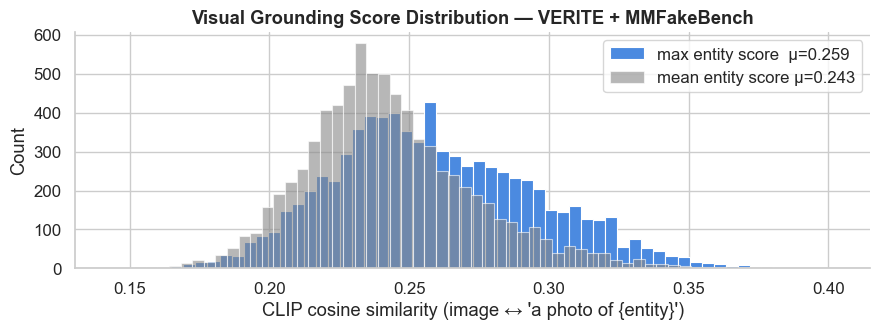

In [89]:
# Build a flat score list from VERITE + MMFakeBench (only datasets with real scores)
active_vg = {**verite_vg, **mmfake_vg}

all_max_scores = []   # max entity-image sim per pair
all_mean_scores = []
n_entities_list = []

for pid, scores in active_vg.items():
    if scores:
        vals = list(scores.values())
        all_max_scores.append(max(vals))
        all_mean_scores.append(np.mean(vals))
        n_entities_list.append(len(vals))

print(f"  Pairs with VG scores : {len(all_max_scores):,}")
print(f"  Max-score  — mean: {np.mean(all_max_scores):.3f}  "
      f"median: {np.median(all_max_scores):.3f}  "
      f"std: {np.std(all_max_scores):.3f}")
print(f"  Mean-score — mean: {np.mean(all_mean_scores):.3f}  "
      f"median: {np.median(all_mean_scores):.3f}")

# Score distribution
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(all_max_scores, bins=60, color="#4B8AE0", edgecolor="white", linewidth=0.8,
        label=f"max entity score  μ={np.mean(all_max_scores):.3f}")
ax.hist(all_mean_scores, bins=60, color="#888888", alpha=0.6, edgecolor="white",
        linewidth=0.8, label=f"mean entity score μ={np.mean(all_mean_scores):.3f}")
ax.set_title("Visual Grounding Score Distribution — VERITE + MMFakeBench", fontweight="bold")
ax.set_xlabel("CLIP cosine similarity (image ↔ 'a photo of {entity}')")
ax.set_ylabel("Count")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig("vg_score_distribution")
plt.show()

## 9. OOC vs Genuine grounding scores

  OOC     — mean: 0.260  median: 0.257  n=5,483
  Genuine — mean: 0.258  median: 0.254  n=2,281
  Saved → paper\figures\vg_score_ooc_vs_genuine.png


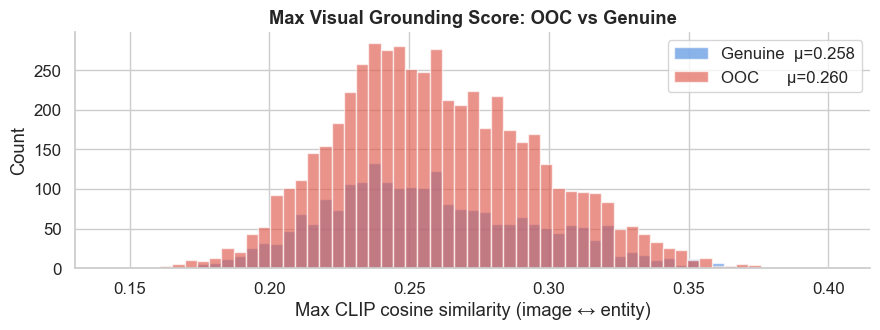

  Saved → paper\tables\vg_stats.csv
  Saved → paper\tables\vg_per_sample_scores.csv


In [90]:
# Re-load dataframes for label info
verite_df = pd.read_csv(VERITE / "VERITE.csv")
# Handle all possible label formats
def binarise_label(val):
    v = str(val).strip().lower()
    if v in ("1", "true", "out-of-context"):
        return 1
    return 0

verite_df["label"] = verite_df["label"].apply(binarise_label)
verite_df["ner_id"] = [f"verite_{i}" for i in range(len(verite_df))]

raw = load_json(DATA / "mmfakebench" / "MMFakeBench_test.json")
mm_pairs = raw if isinstance(raw, list) else list(raw.values())
mmfake_df = pd.DataFrame(mm_pairs)
mmfake_df["label"]  = (mmfake_df["gt_answers"].str.lower() == "fake").astype(int)
mmfake_df["ner_id"] = [f"mmfake_{i}" for i in range(len(mmfake_df))]

ooc_scores, genuine_scores = [], []
rows = []

for df, vg_dict, src in [
    (verite_df,  verite_vg,  "verite"),
    (mmfake_df,  mmfake_vg,  "mmfake"),
]:
    for _, row in df.iterrows():
        scores = vg_dict.get(row["ner_id"], {})
        max_s = max(scores.values()) if scores else np.nan
        lbl = int(row["label"])
        rows.append({"source": src, "label": lbl, "max_vg_score": max_s})
        if not np.isnan(max_s):
            (ooc_scores if lbl == 1 else genuine_scores).append(max_s)

ooc_arr = np.array(ooc_scores)
gen_arr = np.array(genuine_scores)

print(f"  OOC     — mean: {ooc_arr.mean():.3f}  median: {np.median(ooc_arr):.3f}  n={len(ooc_arr):,}")
print(f"  Genuine — mean: {gen_arr.mean():.3f}  median: {np.median(gen_arr):.3f}  n={len(gen_arr):,}")

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(
    min(ooc_arr.min(), gen_arr.min()),
    max(ooc_arr.max(), gen_arr.max()), 60
)
ax.hist(gen_arr, bins=bins, alpha=0.65, color="#4B8AE0",
        label=f"Genuine  μ={gen_arr.mean():.3f}")
ax.hist(ooc_arr, bins=bins, alpha=0.65, color="#E05A4B",
        label=f"OOC      μ={ooc_arr.mean():.3f}")
ax.set_title("Max Visual Grounding Score: OOC vs Genuine", fontweight="bold")
ax.set_xlabel("Max CLIP cosine similarity (image ↔ entity)")
ax.set_ylabel("Count")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig("vg_score_ooc_vs_genuine")
plt.show()

vg_stats_df = pd.DataFrame({
    "class":    ["genuine", "ooc"],
    "mean":     [round(gen_arr.mean(),4), round(ooc_arr.mean(),4)],
    "median":   [round(float(np.median(gen_arr)),4), round(float(np.median(ooc_arr)),4)],
    "std":      [round(gen_arr.std(),4), round(ooc_arr.std(),4)],
    "n_pairs":  [len(gen_arr), len(ooc_arr)],
})
savecsv(vg_stats_df, "vg_stats")
savecsv(pd.DataFrame(rows), "vg_per_sample_scores")

## 10. Sample inspection — top mismatches

In [91]:
# Find pairs where entity score is LOW (entity in caption but not in image)
# These are the most useful examples to show in the paper

print("=== VERITE — lowest grounding scores (likely mismatches) ===")
v_samples = []
for _, row in verite_df.iterrows():
    scores = verite_vg.get(row["ner_id"], {})
    if scores:
        v_samples.append({
            "caption": str(row.get("caption", ""))[:100],
            "label":   int(row["label"]),
            "scores":  scores,
            "max_score": max(scores.values())
        })

v_samples.sort(key=lambda x: x["max_score"])
for s in v_samples[:5]:
    lbl = "OOC" if s["label"] == 1 else "Genuine"
    print(f"\n  [{lbl}] max={s['max_score']:.3f}  {s['caption']}")
    for ent, sc in sorted(s["scores"].items(), key=lambda x: x[1]):
        print(f"    {sc:.3f}  {ent}")

=== VERITE — lowest grounding scores (likely mismatches) ===

  [OOC] max=0.180  Photograph shows a family that was taken away by local epidemic prevention personnel after they had 
    0.172  Hubei Province
    0.180  Photograph

  [Genuine] max=0.184  A photograph shows a sign that reads 'whites only within city limits after dark', taken in a Sundown
    0.184  Sundown

  [OOC] max=0.190  A photo of a schoolteacher writing on a blackboard littered with bullet holes and one giant cavity w
    0.190  Gaza City

  [OOC] max=0.190  A photo of a schoolteacher writing on a blackboard littered with bullet holes and one giant cavity w
    0.190  Gaza City

  [OOC] max=0.191  Image shows an art installation of a giant snake by the Chinese artist Huang Yong Ping is exhibited 
    0.151  Huang Yong Ping
    0.173  Chinese
    0.191  France


## 11. Done

In [92]:
print("=" * 55)
print("  Visual grounding complete.")
print("=" * 55)
print()
print("  Cache files:")
for f in sorted(VG_CACHE.glob("*.pkl")):
    print(f"    {f.name:<45} {f.stat().st_size/1e6:.1f} MB")
print()
print("  Figures (PNG):")
for f in sorted(PAPER_FIGS.glob("vg_*.png")):
    print(f"    {f.name}")
print()
print("  Tables (CSV):")
for f in sorted(PAPER_TABLES.glob("vg_*.csv")):
    print(f"    {f.name}")
print()
print("  Next: notebooks/02_stream_a/entity_scorer.ipynb")

  Visual grounding complete.

  Cache files:
    vg_all.pkl                                    1.1 MB
    vg_mmfake.pkl                                 0.5 MB
    vg_newsclippings_test.pkl                     0.0 MB
    vg_newsclippings_train.pkl                    0.4 MB
    vg_newsclippings_val.pkl                      0.0 MB
    vg_verite.pkl                                 0.1 MB

  Figures (PNG):
    vg_score_distribution.png
    vg_score_ooc_vs_genuine.png

  Tables (CSV):
    vg_per_sample_scores.csv
    vg_stats.csv

  Next: notebooks/02_stream_a/entity_scorer.ipynb


In [93]:
# Run this quick check
import pickle
from pathlib import Path
vg = pickle.load(open(r"F:\GitHub\eve-rag\cache\visual_grounding\vg_verite.pkl", "rb"))
# Show first 3 non-empty entries
shown = 0
for k, v in vg.items():
    if v:
        print(k, v)
        shown += 1
        if shown == 3: break

verite_0 {'Photograph': 0.18021348118782043, 'Hubei Province': 0.17166216671466827}
verite_1 {'Chinese': 0.19939115643501282, 'COVID-19': 0.17735230922698975}
verite_2 {'Photograph': 0.2009788155555725, 'Hubei Province': 0.19371861219406128}
